# BigMart Sales: Modelling

**Goal:** predict `Item_Outlet_Sales` for the 5,681 test rows; the leaderboard uses **RMSE** (lower is better).
The EDA showed price and the store drive sales, so our model has two parts:
1. **Store multipliers:** sales = price x units, and units depend on the store. A linear regression learns one multiplier per store.
2. **Product-number adjustment:** the two digits at the end of `Item_Identifier` (FDA**15**) carry a small, smooth pattern, which we adjust for.

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_squared_error

df = pd.read_csv("bigmart_clean.csv")      # cleaned in the EDA notebook
enc = pd.read_csv("bigmart_encoded.csv")   # same rows, one-hot encoded (for the baseline)
test = pd.read_csv("test.csv")
target = "Item_Outlet_Sales"

# The product number: the last two characters of Item_Identifier, e.g. "FDA15" -> 15
df["Item_Number"] = df["Item_Identifier"].str[3:].astype(int)
test["Item_Number"] = test["Item_Identifier"].str[3:].astype(int)
print(df.shape, test.shape, "| product numbers from", df["Item_Number"].min(), "to", df["Item_Number"].max(),
      "|", df["Item_Number"].nunique(), "different numbers")
same_stores = sorted(df["Outlet_Identifier"].unique()) == sorted(test["Outlet_Identifier"].unique())
print("Same 10 stores in train and test:", same_stores)

(8523, 13) (5681, 12) | product numbers from 1 to 60 | 60 different numbers
Same 10 stores in train and test: True


## Step 2: The model
Written once as functions, so the same code is used for cross-validation, the tests and the submission.
- **Part 1:** one column per store holding the item's MRP (0 for other stores); linear regression **without an intercept** (price 0 sells 0) gives one multiplier per store.
- **Part 2:** ratio = actual / part 1's prediction; average it per product number (`GROUP BY`), include the 2 neighbouring numbers (the pattern is smooth), and pull it towards 1 with 20 rows' worth of "no effect".

In [2]:
def store_columns(data):
    # one column per store: the item's MRP if the row is from that store, else 0
    # (train and test have the same 10 stores, and get_dummies sorts them, so the columns line up)
    X = pd.get_dummies(data["Outlet_Identifier"], dtype=float)
    return X.mul(data["Item_MRP"], axis=0)

def fit_and_predict(train_rows, new_rows, use_number=True):
    # Part 1: store multipliers
    lr = LinearRegression(fit_intercept=False)
    lr.fit(store_columns(train_rows), train_rows[target])
    prediction = lr.predict(store_columns(new_rows))
    if not use_number:
        return prediction

    # Part 2: product-number adjustment, learnt from the training rows only
    ratio = train_rows[target] / lr.predict(store_columns(train_rows))
    by_number = ratio.groupby(train_rows["Item_Number"]).agg(["sum", "count"])
    by_number = by_number.rolling(3, center=True, min_periods=1).sum()   # each number + its 2 neighbours
    factor = (by_number["sum"] + 20) / (by_number["count"] + 20)        # pulled towards 1
    return prediction * new_rows["Item_Number"].map(factor).values

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

## Step 3: 5-fold cross-validation (baseline vs part 1 vs final model)

In [3]:
X_enc = enc.drop(columns=[target])
scores = {"Plain linear regression": [], "Store multipliers only": [], "Final model": []}
oof = np.zeros(len(df))   # out-of-fold predictions of the final model, for Step 5

for train_idx, val_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(df):
    train_rows, val_rows = df.iloc[train_idx], df.iloc[val_idx]
    plain = LinearRegression().fit(X_enc.iloc[train_idx], df[target].iloc[train_idx])
    scores["Plain linear regression"].append(rmse(val_rows[target], plain.predict(X_enc.iloc[val_idx])))
    part1 = fit_and_predict(train_rows, val_rows, use_number=False)
    scores["Store multipliers only"].append(rmse(val_rows[target], part1))
    oof[val_idx] = fit_and_predict(train_rows, val_rows)
    scores["Final model"].append(rmse(val_rows[target], oof[val_idx]))

results = pd.DataFrame(scores)
results.loc["average"] = results.mean()
results.round(1)

,Plain linear regression,Store multipliers only,Final model
0,1069.1,1015.1,1006.7
1,1128.0,1074.9,1066.0
2,1120.8,1058.6,1048.6
3,1167.6,1101.7,1091.1
4,1170.8,1107.8,1096.3
average,1131.3,1071.6,1061.8


> **Learnt:** Final model **1,061.8**, store multipliers alone 1,071.6, plain linear regression 1,131.3. Part 1 does most of the work (about 60 better); the product-number adjustment adds about 10 more and wins in all 5 folds.

## Step 4: Is the product-number pattern real?
A product code shouldn't matter in a real shop, so two tests:
**unseen products** (`GroupKFold` keeps each product in one fold, so it is tested only on products it never saw) and
**shuffled numbers** (each product gets another product's number; if the pattern were luck, that would help just as much).

In [4]:
folds = list(GroupKFold(n_splits=5).split(df, groups=df["Item_Identifier"]))   # each product in one fold only
numbers = df.groupby("Item_Identifier")["Item_Number"].first()                 # one number per product

def gain(data):
    # change in RMSE from adding part 2, averaged over the 5 unseen-product folds
    changes = []
    for train_idx, val_idx in folds:
        actual = data[target].iloc[val_idx]
        before = rmse(actual, fit_and_predict(data.iloc[train_idx], data.iloc[val_idx], use_number=False))
        changes.append(rmse(actual, fit_and_predict(data.iloc[train_idx], data.iloc[val_idx])) - before)
    return np.mean(changes)

fake_gains = []
for seed in range(10):
    # give every product a random number taken from another product
    fake = pd.Series(np.random.default_rng(seed).permutation(numbers.values), index=numbers.index)
    shuffled = df.copy()
    shuffled["Item_Number"] = df["Item_Identifier"].map(fake)
    fake_gains.append(gain(shuffled))

print(f"Real numbers, change in RMSE on unseen products: {gain(df):.1f}")
print("10 shuffles, change in RMSE:", np.round(fake_gains, 1))

Real numbers, change in RMSE on unseen products: -10.3
10 shuffles, change in RMSE: [2.  1.1 0.7 3.2 1.2 2.8 3.7 1.3 3.6 1.4]


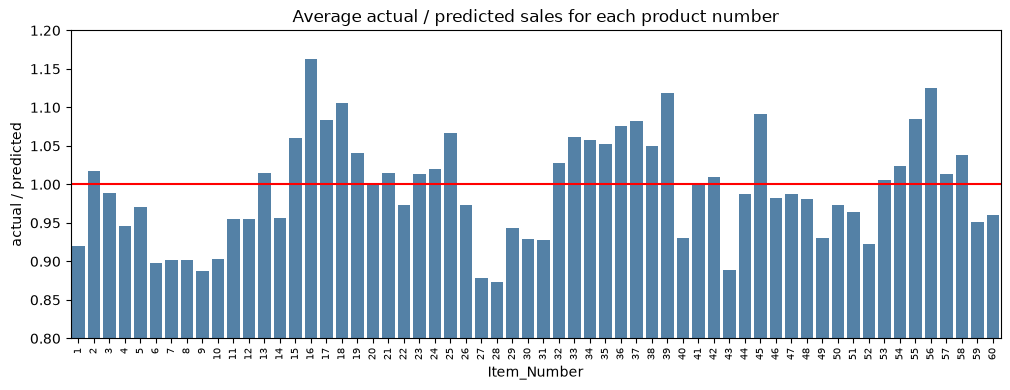

In [5]:
# The pattern: average actual / store-multiplier prediction for each product number
ratio = df[target] / fit_and_predict(df, df, use_number=False)
plt.figure(figsize=(12, 4))
sns.barplot(x=df["Item_Number"], y=ratio, errorbar=None, color="steelblue")
plt.axhline(1, color="red")   # 1 = sells exactly what the store usually sells
plt.xticks(rotation=90, fontsize=7)
plt.ylim(0.8, 1.2)
plt.ylabel("actual / predicted")
plt.title("Average actual / predicted sales for each product number")
plt.show()

> **Learnt:** On unseen products the real numbers lower the error by about 10.3, while all 10 shuffles make it worse (+0.7 to +3.7). So the pattern is real, not luck or memorising products. The plot shows a smooth wave of roughly +/-10% that repeats about every 20 numbers. In a real shop a product code wouldn't matter: this is a quirk of how the dataset was made.

## Step 5: Check the errors (post-model assumptions)

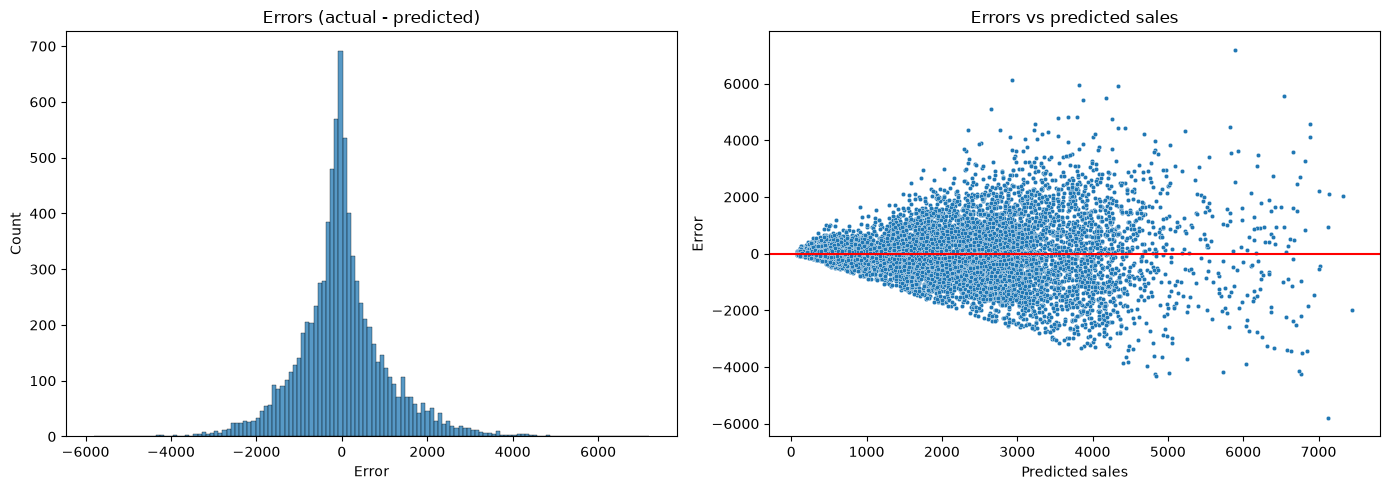

Average error: 9.7


In [6]:
residuals = df[target] - oof   # actual - predicted, using the out-of-fold predictions from Step 3

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(residuals)
plt.xlabel("Error")
plt.title("Errors (actual - predicted)")
plt.subplot(1, 2, 2)
sns.scatterplot(x=oof, y=residuals, s=10)
plt.axhline(0, color="red")
plt.xlabel("Predicted sales")
plt.ylabel("Error")
plt.title("Errors vs predicted sales")
plt.tight_layout()
plt.show()
print(f"Average error: {residuals.mean():.1f}")

> **Learnt:** Errors are centred near 0 (average 9.7) and roughly bell-shaped, so no bias. They fan out for bigger predictions, so homoscedasticity is not fully met; natural, since a busy store selling many units varies more than one selling a few. Durbin-Watson doesn't apply: rows are products, not dates.

## Step 6: Submission and leaderboard

In [7]:
# Learn both parts from all 8,523 training rows, then predict the test rows
test[target] = fit_and_predict(df, test)
submission = test[["Item_Identifier", "Outlet_Identifier", target]]
submission.to_csv("bigmart_submission.csv", index=False)
print(submission.shape)
missing = test[["Item_MRP", "Outlet_Identifier", "Item_Identifier"]].isnull()
print("Missing values in the columns the model uses:", missing.sum().sum())
test[target].describe().round(1)

(5681, 3)
Missing values in the columns the model uses: 0


count    5681.0
mean     2172.1
std      1327.4
min        75.1
25%      1089.8
50%      2073.3
75%      3010.0
max      7360.7
Name: Item_Outlet_Sales, dtype: float64

> **Learnt:** 5,681 predictions from 75.1 to 7,360.7, none negative; no test cleaning needed (MRP, store and product code have no missing values).

**Public leaderboard (Analytics Vidhya, 22 October 2026): RMSE 1,137.62, rank 44 of about 7,400.**
It is higher than our cross-validation RMSE, but so are the leaderboard scores in general (the top of the leaderboard is about 1,122, apart from two entries of exactly 0), so the test rows look harder to predict than the training rows.

## Summary
| Model | 5-fold CV RMSE |
|---|---|
| Plain linear regression (all encoded columns) | 1,131.3 |
| Store multipliers only | 1,071.6 |
| **Final: store multipliers x product-number adjustment** | **1,061.8** |

Predicted sales = store multiplier x MRP x product-number adjustment (10 + 60 numbers). The store and the price drive sales; the product-number pattern is a quirk of this dataset that Step 4 shows is real.
**Limitations:** no prediction for a brand-new store, biggest errors for expensive items in big stores, and the product-number pattern would not exist in real shop data.